# Customer Booking Prediction
British Airways Data Science job simulation on Forage.

Adapted from the supplied starter notebook. Analysis completed by Shramana Das.

Place the authorised simulation dataset `customer_booking.csv` beside this notebook. Saved outputs are from the uploaded analysis; the notebook was not rerun during packaging. Paths were made relative and the repeated starter section and Colab-only download cell were removed.


In [3]:
import pandas as pd

df = pd.read_csv("customer_booking.csv", encoding="ISO-8859-1")

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (50000, 14)


,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0


In [4]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nBooking completion counts:")
print(df["booking_complete"].value_counts())

print("\nBooking completion rate:")
print(f'{df["booking_complete"].mean():.2%}')

Missing values: 0
Duplicate rows: 719

Booking completion counts:
booking_complete
0    42522
1     7478
Name: count, dtype: int64

Booking completion rate:
14.96%


In [5]:
df_clean = df.drop_duplicates().reset_index(drop=True)

print("Rows after removing exact duplicates:", len(df_clean))
print("Remaining duplicates:", df_clean.duplicated().sum())
print(f'Booking completion rate: {df_clean["booking_complete"].mean():.2%}')

Rows after removing exact duplicates: 49281
Remaining duplicates: 0
Booking completion rate: 15.00%


In [6]:
# Summary statistics for numeric columns
display(df_clean.describe().round(2))

# Number of distinct values in each column
display(df_clean.nunique().sort_values())

# Booking completion by sales channel
display(
    df_clean.groupby("sales_channel")["booking_complete"]
    .agg(records="size", completion_rate="mean")
    .round(3)
)

,num_passengers,purchase_lead,length_of_stay,flight_hour,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
count,49281.00,49281.00,49281.00,49281.00,49281.00,49281.00,49281.00,49281.00,49281.00
mean,1.59,84.72,23.05,9.07,0.67,0.30,0.43,7.28,0.15
std,1.02,90.41,33.83,5.41,0.47,0.46,0.49,1.50,0.36
min,1.00,0.00,0.00,0.00,0.00,0.00,0.00,4.67,0.00
25%,1.00,21.00,5.00,5.00,0.00,0.00,0.00,5.62,0.00
50%,1.00,51.00,17.00,9.00,1.00,0.00,0.00,7.57,0.00
75%,2.00,115.00,28.00,13.00,1.00,1.00,1.00,8.83,0.00
max,9.00,867.00,778.00,23.00,1.00,1.00,1.00,9.50,1.00


,0
sales_channel,2
wants_in_flight_meals,2
wants_preferred_seat,2
wants_extra_baggage,2
booking_complete,2
trip_type,3
flight_day,7
num_passengers,9
flight_duration,21
flight_hour,24


,records,completion_rate
sales_channel,,
Internet,43917,0.155
Mobile,5364,0.110


In [7]:
feature_cols = [
    c for c in df_clean.columns
    if c != "booking_complete"
]

profile_outcomes = (
    df_clean.groupby(feature_cols, dropna=False)["booking_complete"]
    .nunique()
)

print(
    "Input profiles with both booking outcomes:",
    (profile_outcomes > 1).sum()
)

print("\nBooking completion by sales channel:")
display(
    df_clean.groupby("sales_channel")["booking_complete"]
    .agg(records="size", completion_rate="mean")
    .round(3)
)

Input profiles with both booking outcomes: 8

Booking completion by sales channel:


,records,completion_rate
sales_channel,,
Internet,43917,0.155
Mobile,5364,0.110


In [8]:
from sklearn.model_selection import StratifiedGroupKFold

X = df_clean.drop(columns="booking_complete")
y = df_clean["booking_complete"]

# Give identical input profiles the same group ID
groups = df_clean.groupby(
    list(X.columns), dropna=False
).ngroup()

splitter = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()
groups_train = groups.iloc[train_idx].copy()

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print(f"Training booking rate: {y_train.mean():.2%}")
print(f"Test booking rate: {y_test.mean():.2%}")
print(
    "Shared profiles:",
    len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))
)

Training rows: 39423
Test rows: 9858
Training booking rate: 15.03%
Test booking rate: 14.88%
Shared profiles: 0


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_cols = [
    c for c in X_train.columns
    if c not in categorical_cols
]

preprocessor = ColumnTransformer([
    ("categories", OneHotEncoder(handle_unknown="ignore"),
     categorical_cols),
    ("numbers", "passthrough", numeric_cols)
])

model = Pipeline([
    ("preparation", preprocessor),
    ("forest", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

print("Model setup complete.")
print("Categorical columns:", categorical_cols)
print("Numeric columns:", numeric_cols)

Model setup complete.
Categorical columns: ['sales_channel', 'trip_type', 'flight_day', 'route', 'booking_origin']
Numeric columns: ['num_passengers', 'purchase_lead', 'length_of_stay', 'flight_hour', 'wants_extra_baggage', 'wants_preferred_seat', 'wants_in_flight_meals', 'flight_duration']


In [10]:
from sklearn.model_selection import cross_validate

cv = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)

scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "balanced_accuracy": "balanced_accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

cv_results = cross_validate(
    model,
    X_train,
    y_train,
    groups=groups_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

cv_summary = pd.DataFrame({
    metric: cv_results[f"test_{metric}"]
    for metric in scoring
}).agg(["mean", "std"]).T

print("Cross-validation results:")
display(cv_summary.round(3))

Cross-validation results:


,mean,std
roc_auc,0.780,0.005
average_precision,0.365,0.021
balanced_accuracy,0.721,0.006
precision,0.304,0.012
recall,0.743,0.016
f1,0.432,0.012


In [11]:
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    balanced_accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)

model.fit(X_train, y_train)

test_probability = model.predict_proba(X_test)[:, 1]
test_prediction = model.predict(X_test)

test_results = pd.Series({
    "ROC-AUC": roc_auc_score(y_test, test_probability),
    "Average precision": average_precision_score(
        y_test, test_probability
    ),
    "Balanced accuracy": balanced_accuracy_score(
        y_test, test_prediction
    ),
    "Precision": precision_score(y_test, test_prediction),
    "Recall": recall_score(y_test, test_prediction),
    "F1": f1_score(y_test, test_prediction)
})

display(test_results.round(3))

print("\nConfusion matrix: rows = actual, columns = predicted")
print(confusion_matrix(y_test, test_prediction))

print(f"\nNo-skill average precision baseline: {y_test.mean():.3f}")

,0
ROC-AUC,0.774
Average precision,0.340
Balanced accuracy,0.715
Precision,0.296
Recall,0.737
F1,0.422



Confusion matrix: rows = actual, columns = predicted
[[5821 2570]
 [ 386 1081]]

No-skill average precision baseline: 0.149


,Variable,Importance,Std
8,booking_origin,0.1160,0.0071
7,route,0.0262,0.0045
4,length_of_stay,0.0185,0.0049
9,wants_extra_baggage,0.0137,0.0018
12,flight_duration,0.0092,0.0017
10,wants_preferred_seat,0.0069,0.0014
3,purchase_lead,0.0047,0.0011
1,sales_channel,0.0029,0.0007
0,num_passengers,0.0023,0.0009
11,wants_in_flight_meals,0.0021,0.0014


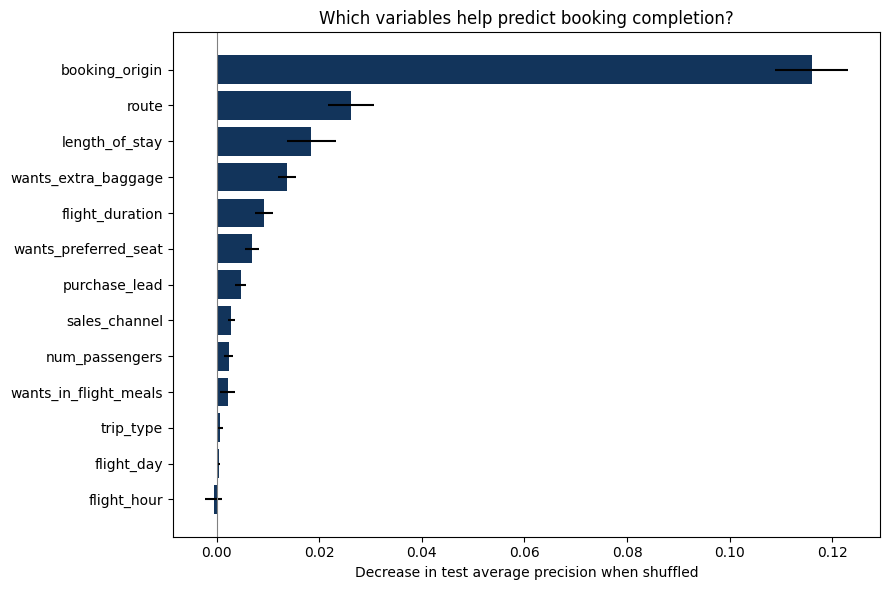

In [12]:
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    model,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

importance_table = pd.DataFrame({
    "Variable": X_test.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values("Importance", ascending=False)

display(importance_table.round(4))

chart_data = importance_table.sort_values("Importance")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(
    chart_data["Variable"],
    chart_data["Importance"],
    xerr=chart_data["Std"],
    color="#12345B"
)
ax.axvline(0, color="grey", linewidth=0.8)
ax.set_xlabel("Decrease in test average precision when shuffled")
ax.set_title("Which variables help predict booking completion?")
fig.tight_layout()

fig.savefig(
    "booking_variable_importance.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()